# PRAKTIKUM PENAMBANGAN DATA (PPD)
## MODUL 8: NEURAL NETWORK (MULTILAYER PERCEPTRON)

* **Nama**: Januarsyah Akbar
* **NIM**: 24/535846/SV/24314
* **Kelas**: B2
* **Mata Kuliah**: Praktikum Penambangan Data (SVPL214610)
* **Program Studi**: D4 Teknologi Rekayasa Perangkat Lunak, Sekolah Vokasi UGM

---

### 1. Inisialisasi & Setup Lingkungan
Menyiapkan folder data, dependensi pustaka, dan jalur akses dataset agar notebook dapat dieksekusi secara mulus di Google Colab maupun di lingkungan lokal.

In [1]:
import os
import urllib.request
import ssl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan folder data tersedia
data_dirs = ['data', '../data', 'P8/project/data', '../project/data']
DATA_DIR = 'data'
for d in data_dirs:
    if os.path.exists(d):
        DATA_DIR = d
        break

print(f"Menggunakan direktori data: {DATA_DIR}")


Menggunakan direktori data: P8/project/data


### 2. Import Pustaka Pembelajaran Mesin & Neural Network
Mengimpor modul manipulasi data, visualisasi, pra-pemrosesan, serta arsitektur Multilayer Perceptron (`MLPClassifier` dan `MLPRegressor`) dari `scikit-learn`.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    r2_score,
    mean_absolute_error,
    classification_report
)

# Atur gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
print("Seluruh pustaka berhasil diimpor.")


Seluruh pustaka berhasil diimpor.


---
## A. LANGKAH PERCOBAAN 1: MULTILAYER PERCEPTRON UNTUK KLASIFIKASI (BANK CUSTOMER CHURN)

Percobaan ini bertujuan untuk mengklasifikasikan apakah seorang nasabah kartu kredit bank akan bertahan (*Existing Customer*) atau berhenti berlangganan (*Attrited Customer*) berdasarkan fitur demografis dan transaksi finansial.

#### a. Membaca Dataset Bank Customer Churn

In [3]:
churn_file = os.path.join(DATA_DIR, 'BankChurners.csv')
df_churn = pd.read_csv(churn_file)

# Menampilkan 5 baris data teratas
df_churn.head()


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


#### b. Menganalisis Distribusi Variabel Menggunakan Histogram

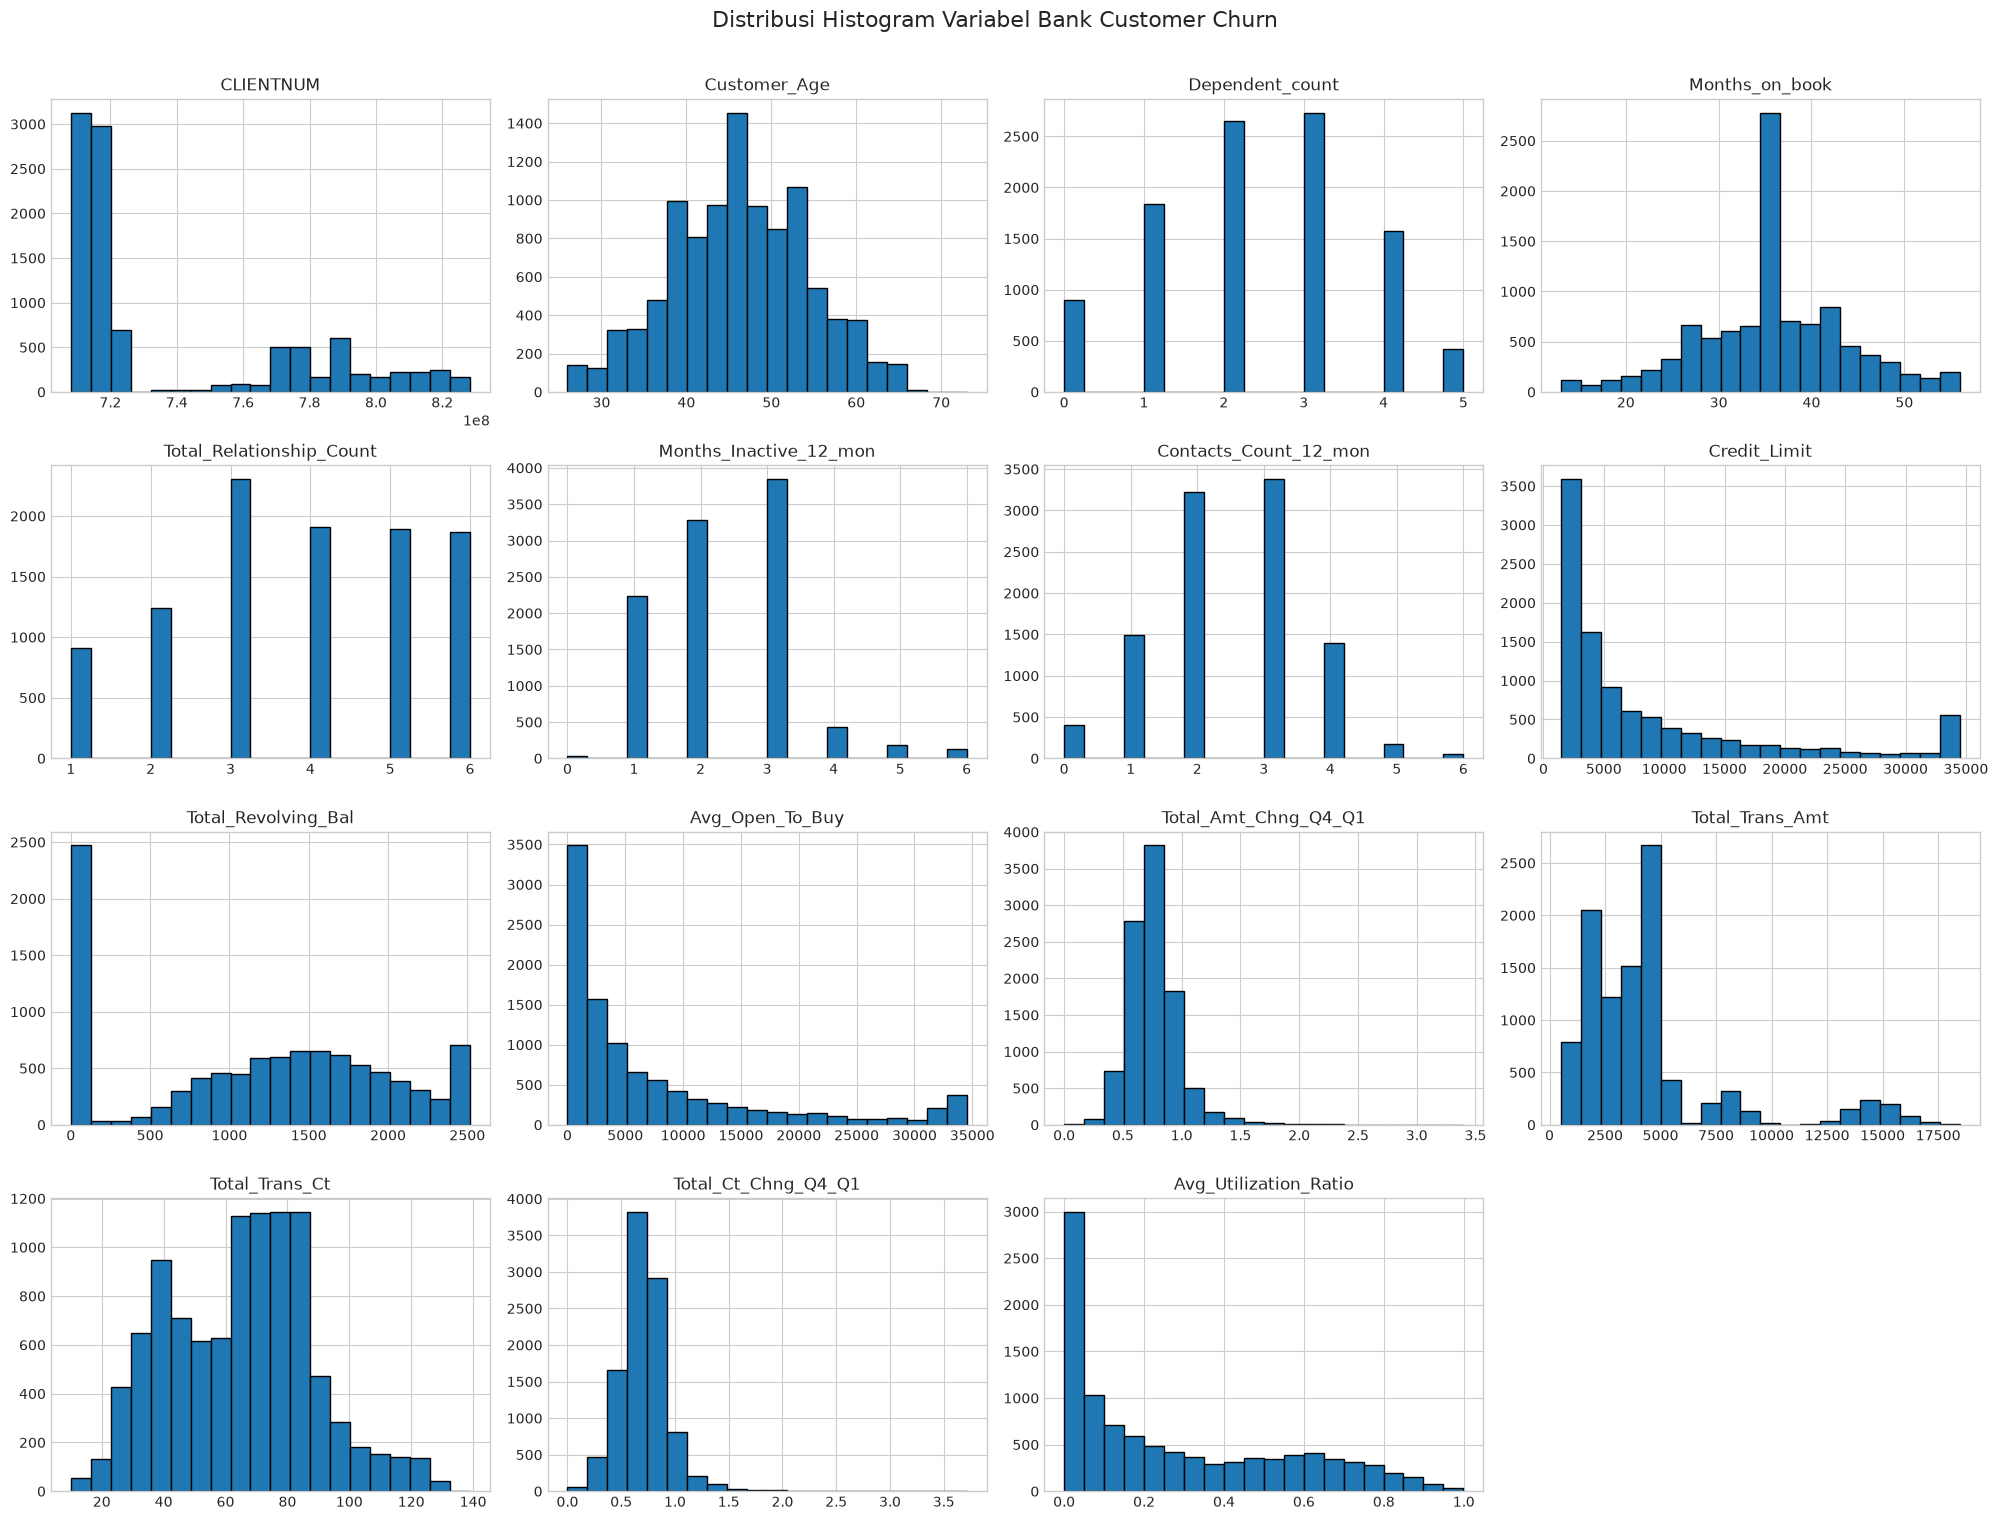

In [4]:
df_churn.hist(figsize=(20, 15), bins=20, edgecolor='black', grid=True)
plt.suptitle('Distribusi Histogram Variabel Bank Customer Churn', fontsize=16, y=1.01)
plt.show()


#### c. Mengecek Proporsi Target Class (`Attrition_Flag`)

Jumlah masing-masing kelas target:
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64


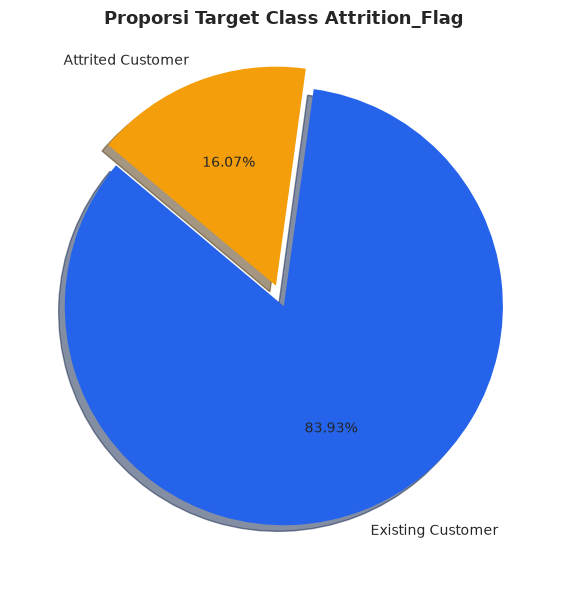

In [5]:
target_counts = df_churn['Attrition_Flag'].value_counts()
print("Jumlah masing-masing kelas target:")
print(target_counts)

plt.figure(figsize=(7, 6))
target_counts.plot(
    kind='pie',
    autopct='%1.2f%%',
    colors=['#2563eb', '#f59e0b'],
    startangle=140,
    explode=(0, 0.1),
    shadow=True
)
plt.title("Proporsi Target Class Attrition_Flag", fontsize=13, fontweight='bold')
plt.ylabel("")
plt.show()


#### d. Mengecek Nilai Hilang (*Missing Values*)

In [6]:
missing_churn = df_churn.isnull().sum()
print("Jumlah nilai null per atribut:")
print(missing_churn)


Jumlah nilai null per atribut:
CLIENTNUM                   0
Attrition_Flag              0
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
dtype: int64


#### e. Mengidentifikasi Atribut Kategorikal dan Numerik

In [7]:
# Menentukan fitur input X dan target y
df_X = df_churn.drop(['CLIENTNUM', 'Attrition_Flag'], axis=1)
df_y = df_churn[['Attrition_Flag']]

# Cek atribut bertipe kategorikal
cats = df_X.select_dtypes(include=['object', 'bool', 'str']).columns
print("Atribut Kategorikal:")
print(cats)

nums = df_X.select_dtypes(include=[np.number]).columns
print("\nAtribut Numerik:")
print(nums)


Atribut Kategorikal:
Index(['Gender', 'Education_Level', 'Marital_Status', 'Income_Category',
       'Card_Category'],
      dtype='str')

Atribut Numerik:
Index(['Customer_Age', 'Dependent_count', 'Months_on_book',
       'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
       'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio'],
      dtype='str')


#### f. Encoding Variabel, Pembagian Data Train-Test, dan Pelatihan Model MLPClassifier

In [8]:
# 1. Encoding variabel target y (Existing Customer vs Attrited Customer)
le_y = LabelEncoder()
df_y_encoded = le_y.fit_transform(df_y['Attrition_Flag'])

# 2. Categorical encoding pada fitur input X menggunakan LabelEncoder
cat_features = list(cats.values)
le_dict = {}
df_X_encoded = df_X.copy()
for col in cat_features:
    le_col = LabelEncoder()
    df_X_encoded[col] = le_col.fit_transform(df_X_encoded[col].astype(str))
    le_dict[col] = le_col

# 3. Konversi menjadi array numpy
X = df_X_encoded.astype(float).values
y = df_y_encoded.astype(float)

# 4. Hold-out method pembagian dataset (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 5. Standarisasi fitur numerik dengan StandardScaler
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Membangun dan melatih model MLPClassifier
model_mlp = MLPClassifier(max_iter=500, random_state=42)
model_mlp.fit(X_train_scaled, y_train)

print("Pelatihan MLPClassifier selesai!")
print(f"Iterasi konvergensi: {model_mlp.n_iter_}")
print(f"Jumlah lapisan (n_layers_): {model_mlp.n_layers_}")


Pelatihan MLPClassifier selesai!
Iterasi konvergensi: 500
Jumlah lapisan (n_layers_): 3


/Users/mrfrog/Documents/Kuliah/PPD/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


#### g. Inspeksi Koefisien Model (*Weights* dan *Biases*)

In [9]:
# Menampilkan dimensi koefisien bobot tiap lapisan
for i, coef in enumerate(model_mlp.coefs_):
    print(f"Lapisan {i} -> Bobot shape: {coef.shape}")

print("\nContoh koefisien bobot pada lapisan pertama (5 baris teratas):")
print(model_mlp.coefs_[0][:5, :5])


Lapisan 0 -> Bobot shape: (19, 100)
Lapisan 1 -> Bobot shape: (100, 1)

Contoh koefisien bobot pada lapisan pertama (5 baris teratas):
[[-0.3857342   0.10840396  0.79216726  0.37675418 -0.42662128]
 [-0.86985632  0.02028376  0.07048071  0.15883154 -0.04721517]
 [-0.15697107 -0.33563439 -0.27627508  0.00621799  0.08814956]
 [-0.10189953  0.08670851 -0.22915727 -0.07048618 -0.19380853]
 [-0.00866776  0.32470209  0.04354969  0.09670708 -0.03749813]]


#### h. Visualisasi Data Ter-Preprocessing (`df_X` dan `X_train[0]`)

In [10]:
print("Pratinjau Dataframe Input Fitur Setelah Encoding (df_X.head()):")
display(df_X_encoded.head())

print("\nRepresentasi vektor numerik satu baris data latih setelah standarisasi (X_train[0]):")
print(X_train_scaled[0])


Pratinjau Dataframe Input Fitur Setelah Encoding (df_X.head()):


,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,45,1,3,3,1,2,0,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,49,0,5,2,2,4,0,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,51,1,3,2,1,3,0,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,40,0,4,3,3,4,0,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,40,1,3,5,1,2,0,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000



Representasi vektor numerik satu baris data latih setelah standarisasi (X_train[0]):
[ 0.33519339  1.05692234 -0.25437357  0.4990858  -0.61710507 -0.56580813
 -0.25591165  0.25586758 -0.51407227 -0.33752656 -2.22835505 -0.05917368
  0.98686487 -0.14826286 -0.57038549 -0.90317904 -1.65490765 -1.12681489
 -0.11093226]


#### i. Evaluasi Performa Model Klasifikasi

Accuracy         : 0.9381 (93.81%)
Precision        : 0.9605
Recall           : 0.9658
F1-Score         : 0.9631
Confusion Matrix :
[[ 395  101]
 [  87 2456]]


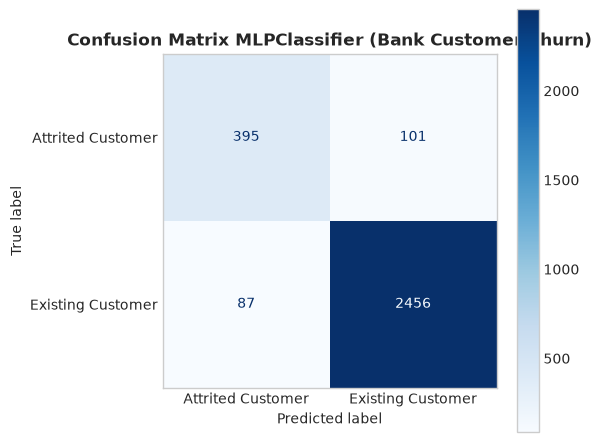

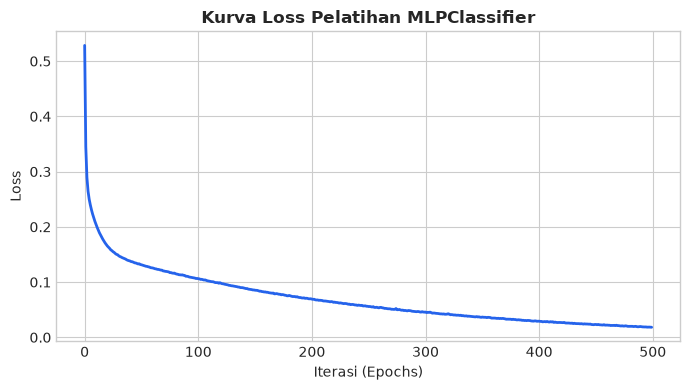

In [11]:
# Prediksi pada data uji
y_pred = model_mlp.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy         : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision        : {prec:.4f}")
print(f"Recall           : {rec:.4f}")
print(f"F1-Score         : {f1:.4f}")
print(f"Confusion Matrix :\n{cm}")

# Visualisasi Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_y.classes_)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Confusion Matrix MLPClassifier (Bank Customer Churn)", fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()

# Visualisasi Kurva Loss Selama Pelatihan
plt.figure(figsize=(7, 4))
plt.plot(model_mlp.loss_curve_, color='#2563eb', lw=2)
plt.title("Kurva Loss Pelatihan MLPClassifier", fontsize=12, fontweight='bold')
plt.xlabel("Iterasi (Epochs)")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


#### j. Melatih Model dan Menguji Prediksi Data Inferensi Baru
Menguji sampel data nasabah baru untuk memprediksi apakah nasabah tersebut berpotensi *churn* atau bertahan.

In [12]:
# Sampel data baru dari modul
sample_customer = [{
    'Customer_Age': 58,
    'Gender': 'F',
    'Dependent_count': 1,
    'Education_Level': 'Graduate',
    'Marital_Status': 'Single',
    'Income_Category': 'Less than $40K',
    'Card_Category': 'Blue',
    'Months_on_book': 44,
    'Total_Relationship_Count': 5,
    'Months_Inactive_12_mon': 2,
    'Contacts_Count_12_mon': 2,
    'Credit_Limit': 4780,
    'Total_Revolving_Bal': 800,
    'Avg_Open_To_Buy': 3982,
    'Total_Amt_Chng_Q4_Q1': 1.543,
    'Total_Trans_Amt': 1388,
    'Total_Trans_Ct': 32,
    'Total_Ct_Chng_Q4_Q1': 2.714,
    'Avg_Utilization_Ratio': 0.167
}]

df_input = pd.DataFrame(sample_customer)

# Encoding atribut kategorikal dengan encoder yang sama
for col in cat_features:
    df_input[col] = le_dict[col].transform(df_input[col].astype(str))

# Standarisasi fitur dengan scaler yang sama
df_input_scaled = scaler.transform(df_input.astype(float).values)

# Prediksi kelas dan probabilitas
pred_code = model_mlp.predict(df_input_scaled)
pred_label = le_y.inverse_transform(pred_code.astype(int))
pred_proba = model_mlp.predict_proba(df_input_scaled)

print(f"Hasil Kode Prediksi       : {pred_code[0]}")
print(f"Hasil Interpretasi Label  : {pred_label[0]}")
print(f"Probabilitas Prediksi     : {pred_proba[0]}")
print(f"Keterangan: Nasabah diprediksi akan menjadi '{pred_label[0]}' dengan keyakinan {np.max(pred_proba)*100:.2f}%.")


Hasil Kode Prediksi       : 1.0
Hasil Interpretasi Label  : Existing Customer
Probabilitas Prediksi     : [9.69047065e-12 1.00000000e+00]
Keterangan: Nasabah diprediksi akan menjadi 'Existing Customer' dengan keyakinan 100.00%.


---
## B. LANGKAH PERCOBAAN 2: MULTILAYER PERCEPTRON UNTUK REGRESI (KC HOUSE PRICE PREDICTION)

Percobaan ini bertujuan untuk memprediksi nilai kontinu berupa harga rumah (*price*) di King County, Washington menggunakan arsitektur `MLPRegressor`.

#### a. Membaca Dataset KC House

In [13]:
kc_file = os.path.join(DATA_DIR, 'kc_house_data.csv')
df_kc = pd.read_csv(kc_file)

# Menampilkan 5 baris pertama
df_kc.head()


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


#### b. Mengecek Nilai Hilang (*Missing Values*)

In [14]:
print("Pengecekan Missing Value pada KC House Data:")
print(df_kc.isnull().sum())


Pengecekan Missing Value pada KC House Data:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


#### c. Menampilkan Histogram Fitur Numerik KC House

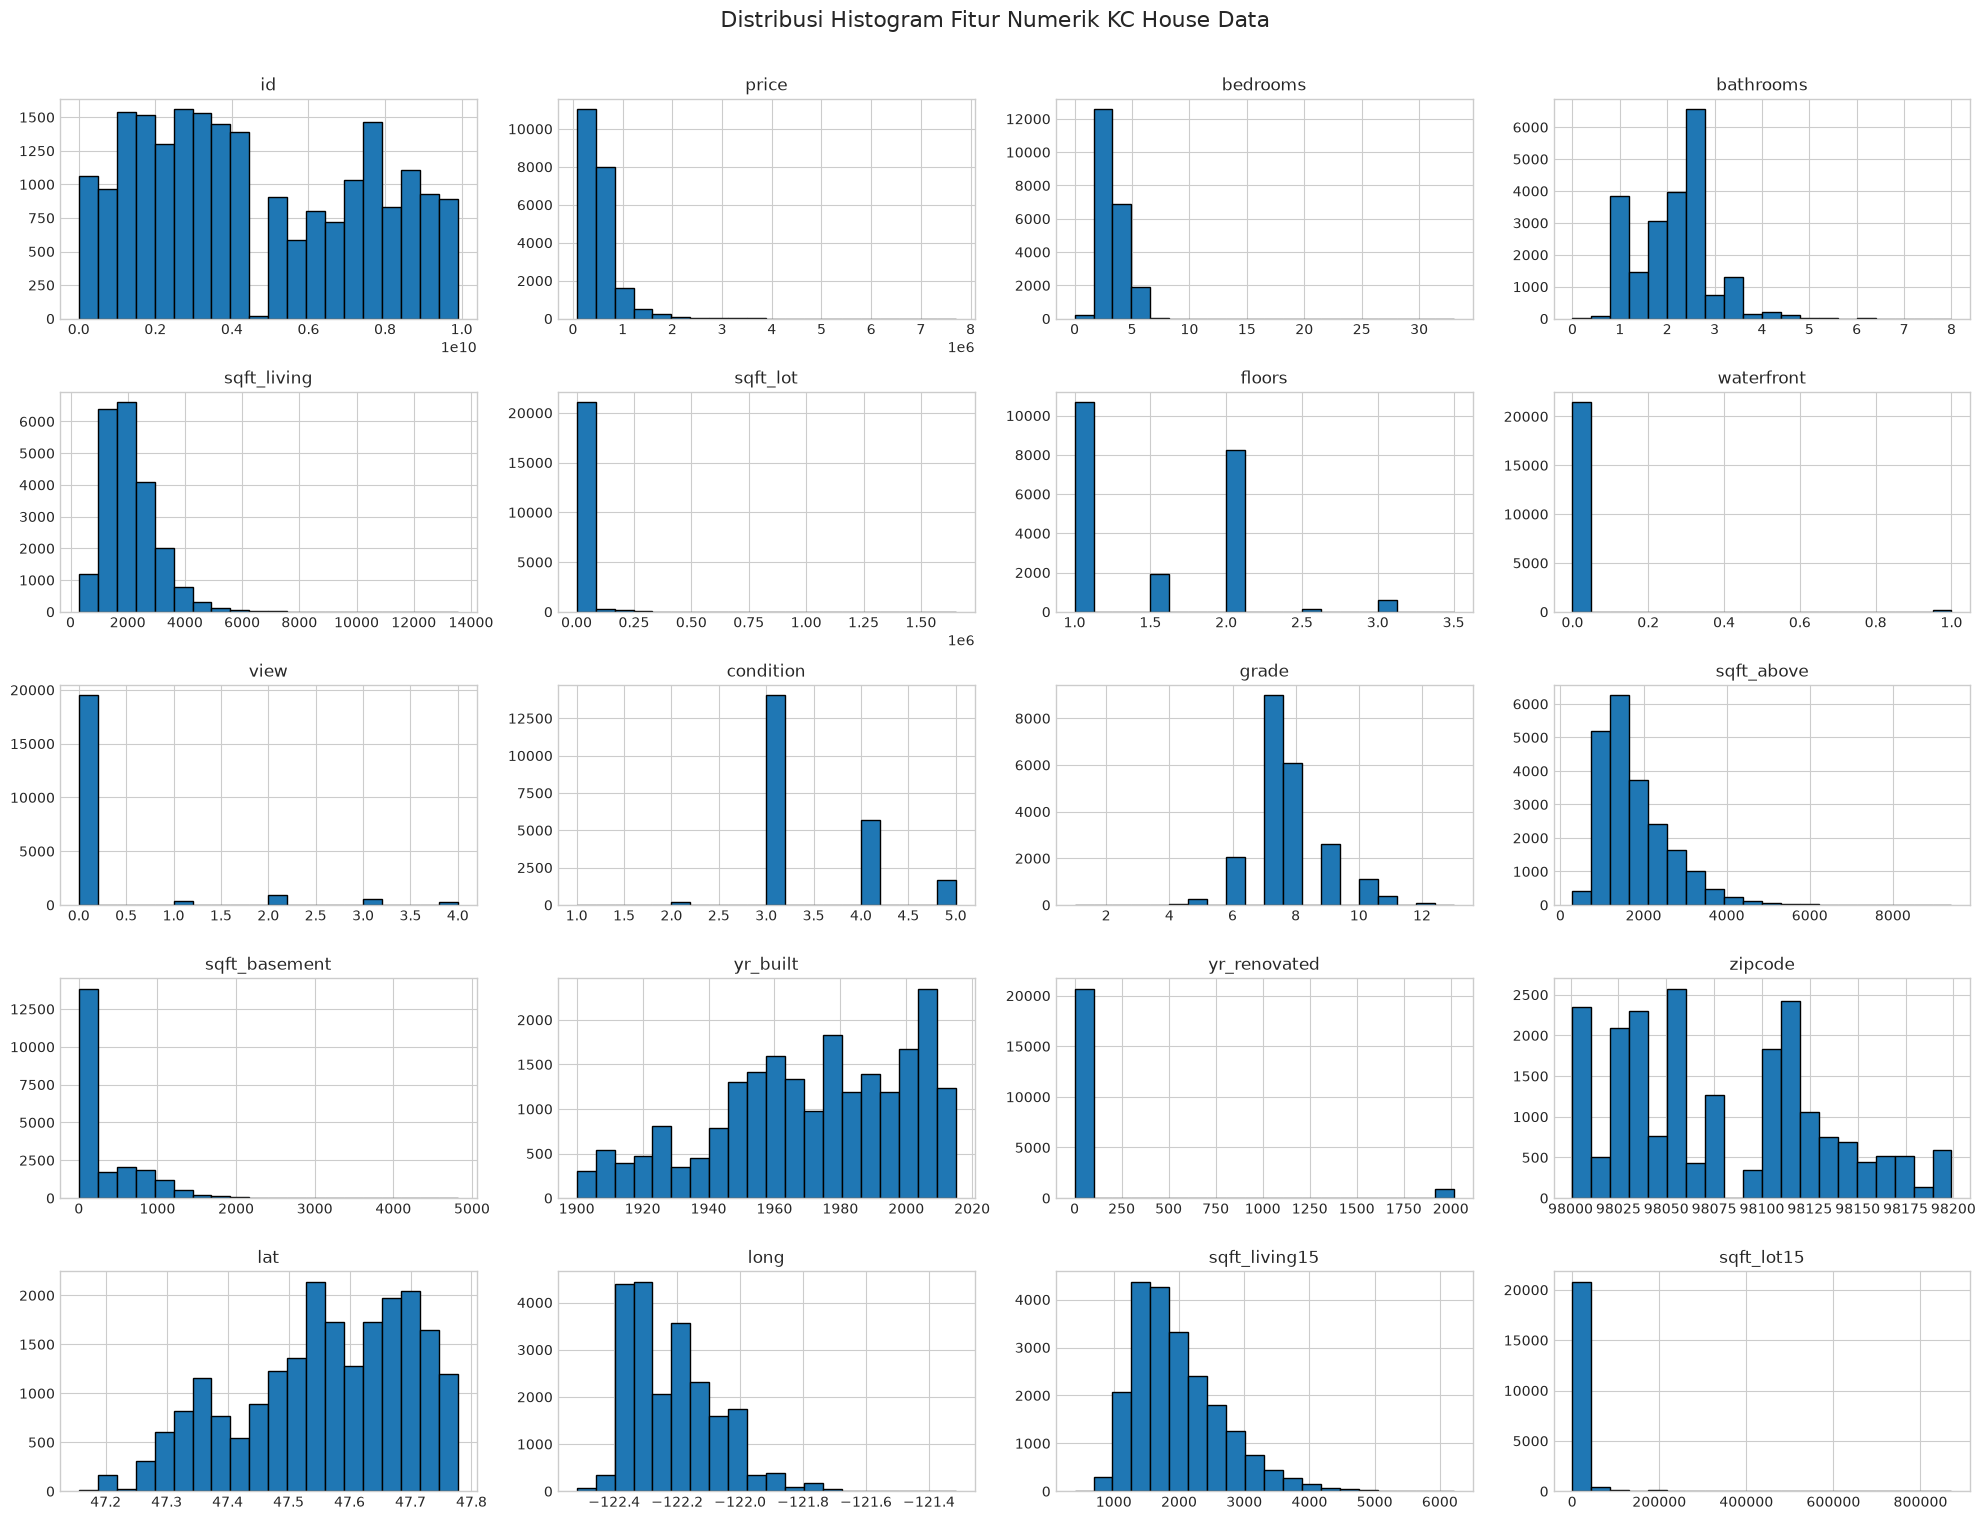

In [15]:
df_kc.hist(figsize=(20, 15), bins=20, edgecolor='black', grid=True)
plt.suptitle('Distribusi Histogram Fitur Numerik KC House Data', fontsize=16, y=1.01)
plt.show()


#### d. Menyiapkan Atribut Fitur dan Pemisahan Data

In [16]:
# Menghilangkan kolom id, date, dan target price
df_X_kc = df_kc.drop(['id', 'date', 'price'], axis=1)
df_y_kc = df_kc['price']

cats_kc = df_X_kc.select_dtypes(include=['object', 'bool']).columns
print("Atribut Kategorikal:", cats_kc)

# Imputasi nilai hilang dengan nilai rata-rata (mean imputer)
imputer = SimpleImputer(strategy='mean')
X_kc = imputer.fit_transform(df_X_kc)
y_kc = df_y_kc.astype(float).values

# Membagi data menjadi 70% data latih dan 30% data uji
X_train_kc, X_test_kc, y_train_kc, y_test_kc = train_test_split(
    X_kc, y_kc, test_size=0.3, random_state=42
)

print(f"Dimensi data latih: {X_train_kc.shape}")
print(f"Dimensi data uji  : {X_test_kc.shape}")


Atribut Kategorikal: Index([], dtype='str')
Dimensi data latih: (15129, 18)
Dimensi data uji  : (6484, 18)


#### e. Melatih Model MLPRegressor dan Menguji Koefisien Determinasi ($R^2$)

In [17]:
# Membangun dan melatih model MLPRegressor
reg_kc = MLPRegressor(max_iter=500, random_state=42)
reg_kc.fit(X_train_kc, y_train_kc)

r2_train = reg_kc.score(X_train_kc, y_train_kc)
r2_test = reg_kc.score(X_test_kc, y_test_kc)

print(f"coef of determination training : {r2_train}")
print(f"coef of determination testing  : {r2_test}")

# Menampilkan 10 prediksi awal vs nilai asli
y_pred_kc = reg_kc.predict(X_test_kc)

print("\nPrediksi 10 data pertama:")
print(np.round(y_pred_kc[:10], 2))
print("\nNilai asli 10 data pertama:")
print(y_test_kc[:10])


coef of determination training : 0.5732472046869872
coef of determination testing  : 0.5540121047079314

Prediksi 10 data pertama:
[ 508376.62  734989.1  1126392.7  1414138.68  598096.25  422785.56
  626903.36  509875.77  464562.01  392782.78]

Nilai asli 10 data pertama:
[ 365000.  865000. 1038000. 1490000.  711000.  211000.  790000.  680000.
  384500.  605000.]


#### f. Mengukur Performa Regresi dengan Metrik $R^2$ dan RMSE

In [18]:
mse_kc = mean_squared_error(y_test_kc, y_pred_kc)
rmse_kc = np.sqrt(mse_kc)
r2_kc = r2_score(y_test_kc, y_pred_kc)

print(f"rmse : {rmse_kc:.4f}")
print(f"r2   : {r2_kc:.4f}")


rmse : 253743.4247
r2   : 0.5540


#### g. Visualisasi Perbandingan Nilai Asli vs Prediksi (30 Sampel Pertama)

<Figure size 1400x600 with 0 Axes>

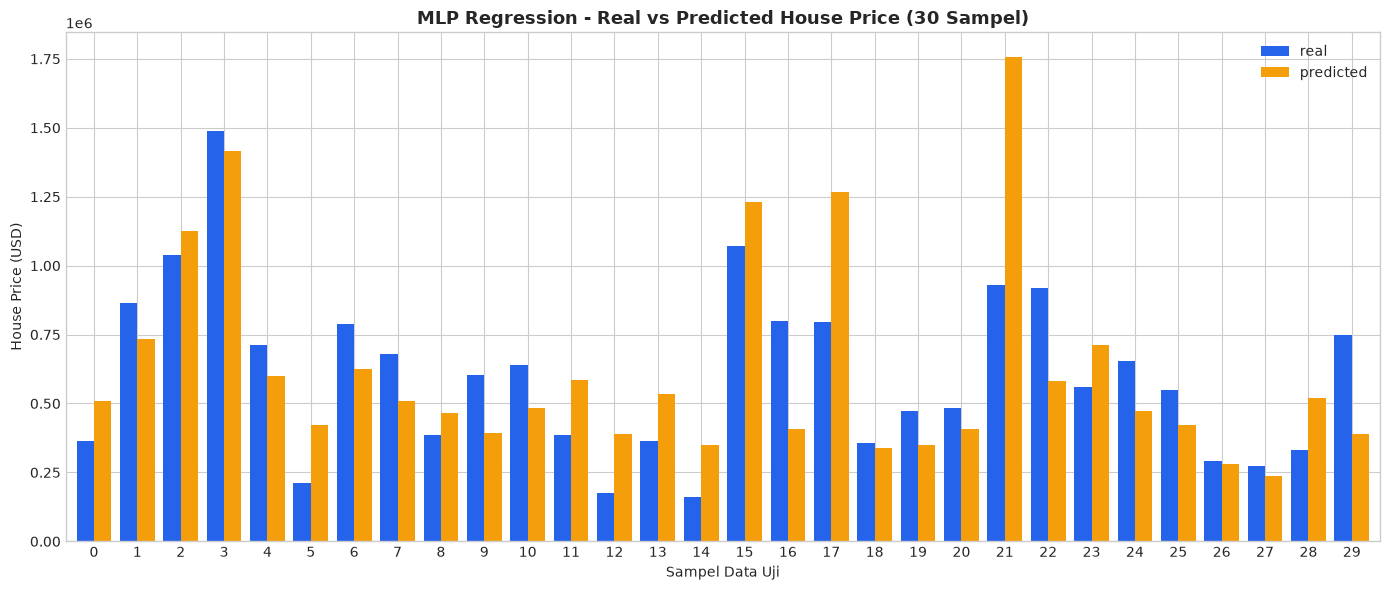

In [19]:
data_real = pd.DataFrame(y_test_kc[:30], columns=['real'])
data_pred = pd.DataFrame(y_pred_kc[:30], columns=['predicted'])
df_comp_kc = pd.concat([data_real, data_pred], axis=1)

plt.figure(figsize=(14, 6))
df_comp_kc.plot(kind='bar', figsize=(14, 6), color=['#2563eb', '#f59e0b'], width=0.8)
plt.title("MLP Regression - Real vs Predicted House Price (30 Sampel)", fontsize=13, fontweight='bold')
plt.xlabel("Sampel Data Uji")
plt.ylabel("House Price (USD)")
plt.xticks(rotation=0)
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()


---
## C. TUGAS 1: ANALISIS KARAKTERISTIK DAN FITUR DATASET

### 1. Tujuan Masing-Masing Dataset
* **Bank Customer Churn Dataset (`BankChurners.csv`)**:
  Dataset ini bertujuan untuk menganalisis perilaku pelanggan kartu kredit dan memprediksi kecenderungan nasabah untuk berhenti menggunakan layanan (*churn*) atau tetap aktif (*attrition flag*). Pemodelan prediktif berbasis dataset ini sangat vital bagi perbankan guna merancang strategi retensi pelanggan, meningkatkan kepuasan, dan meminimalkan kerugian finansial akibat kehilangan basis nasabah.
* **KC House Sales Dataset (`kc_house_data.csv`)**:
  Dataset ini merekam data transaksi penjualan properti residensial di King County, Washington (mencakup Seattle) antara Mei 2014 hingga Mei 2015. Tujuannya adalah memodelkan hubungan kuantitatif antara atribut fisik rumah, lokasi geografis, kondisi struktural, dan faktor lingkungan terhadap nilai jual properti (*price*). Model ini digunakan untuk estimasi valuasi harga properti secara otomatis.

### 2. Deskripsi Fitur Dataset
Tabel deskripsi rinci dari kedua dataset disajikan di bawah ini.

In [20]:
# Ringkasan informasi kolom dataset Bank Churn
df_churn_desc = pd.DataFrame({
    'Atribut': df_churn.columns,
    'Tipe Data': [str(t) for t in df_churn.dtypes],
    'Jumlah Non-Null': df_churn.count().values,
    'Jumlah Unik': [df_churn[c].nunique() for c in df_churn.columns],
    'Contoh Nilai': [str(df_churn[c].iloc[0]) for c in df_churn.columns]
})
print("Ringkasan Fitur Bank Customer Churn Dataset:")
display(df_churn_desc)


Ringkasan Fitur Bank Customer Churn Dataset:


,Atribut,Tipe Data,Jumlah Non-Null,Jumlah Unik,Contoh Nilai
0,CLIENTNUM,int64,10127,10127,768805383
1,Attrition_Flag,str,10127,2,Existing Customer
2,Customer_Age,int64,10127,45,45
3,Gender,str,10127,2,M
4,Dependent_count,int64,10127,6,3
5,Education_Level,str,10127,7,High School
6,Marital_Status,str,10127,4,Married
7,Income_Category,str,10127,6,$60K - $80K
8,Card_Category,str,10127,4,Blue
9,Months_on_book,int64,10127,44,39


In [21]:
# Ringkasan informasi kolom dataset KC House
df_kc_desc = pd.DataFrame({
    'Atribut': df_kc.columns,
    'Tipe Data': [str(t) for t in df_kc.dtypes],
    'Jumlah Non-Null': df_kc.count().values,
    'Jumlah Unik': [df_kc[c].nunique() for c in df_kc.columns],
    'Contoh Nilai': [str(df_kc[c].iloc[0]) for c in df_kc.columns]
})
print("Ringkasan Fitur KC House Data:")
display(df_kc_desc)


Ringkasan Fitur KC House Data:


,Atribut,Tipe Data,Jumlah Non-Null,Jumlah Unik,Contoh Nilai
0,id,int64,21613,21436,7129300520
1,date,str,21613,372,20141013T000000
2,price,float64,21613,4028,221900.0
3,bedrooms,int64,21613,13,3
4,bathrooms,float64,21613,30,1.0
5,sqft_living,int64,21613,1038,1180
6,sqft_lot,int64,21613,9782,5650
7,floors,float64,21613,6,1.0
8,waterfront,int64,21613,2,0
9,view,int64,21613,5,0


---
## D. TUGAS 2: EKSPERIMEN MODEL MLP PADA DATASET BARU (KLASIFIKASI & REGRESI)

Pada tugas ini, dilakukan pemodelan Multilayer Perceptron pada dua dataset baru:
1. **Klasifikasi**: Pima Indians Diabetes Dataset (`diabetes.csv`) menggunakan `MLPClassifier` untuk mendiagnosis apakah pasien mengidap diabetes berdasarkan indikator medis klinis.
2. **Regresi**: Medical Cost Personal Dataset (`insurance.csv`) menggunakan `MLPRegressor` untuk memprediksi besaran biaya premi tagihan asuransi kesehatan individu.

### Tugas 2A: Klasifikasi Diabetes Menggunakan MLPClassifier

Dimensi dataset diabetes: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



=== HASIL EVALUASI KLASIFIKASI DIABETES (MLPCLASSIFIER) ===
Accuracy  : 0.7273 (72.73%)
Precision : 0.6406
Recall    : 0.5062
F1-Score  : 0.5655

Laporan Klasifikasi Rinci:
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.76      0.85      0.80       150
    Diabetic (1)       0.64      0.51      0.57        81

        accuracy                           0.73       231
       macro avg       0.70      0.68      0.68       231
    weighted avg       0.72      0.73      0.72       231



/Users/mrfrog/Documents/Kuliah/PPD/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


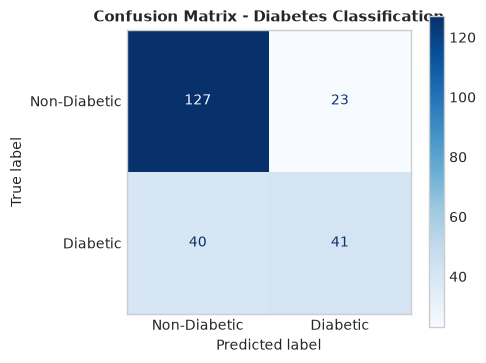

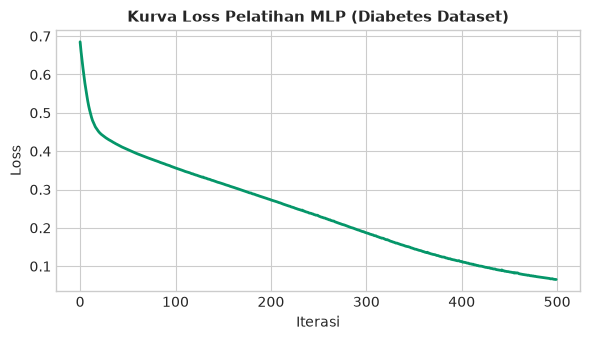

In [22]:
# 1. Membaca dataset diabetes
diab_file = os.path.join(DATA_DIR, 'diabetes.csv')
df_diab = pd.read_csv(diab_file)

print("Dimensi dataset diabetes:", df_diab.shape)
display(df_diab.head())

# 2. Pemisahan Fitur dan Target
X_diab = df_diab.drop('Outcome', axis=1).values
y_diab = df_diab['Outcome'].values

# 3. Pembagian Data Train dan Test (70% Train, 30% Test)
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_diab, y_diab, test_size=0.3, random_state=42, stratify=y_diab
)

# 4. Standarisasi Fitur dengan StandardScaler
scaler_diab = StandardScaler().fit(X_train_d)
X_train_d_s = scaler_diab.transform(X_train_d)
X_test_d_s = scaler_diab.transform(X_test_d)

# 5. Membangun dan Melatih Model MLPClassifier dengan Arsitektur Multi-Layer (64, 32)
mlp_diab = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
mlp_diab.fit(X_train_d_s, y_train_d)

# 6. Prediksi dan Evaluasi
y_pred_d = mlp_diab.predict(X_test_d_s)

acc_d = accuracy_score(y_test_d, y_pred_d)
prec_d = precision_score(y_test_d, y_pred_d)
rec_d = recall_score(y_test_d, y_pred_d)
f1_d = f1_score(y_test_d, y_pred_d)
cm_d = confusion_matrix(y_test_d, y_pred_d)

print("\n=== HASIL EVALUASI KLASIFIKASI DIABETES (MLPCLASSIFIER) ===")
print(f"Accuracy  : {acc_d:.4f} ({acc_d*100:.2f}%)")
print(f"Precision : {prec_d:.4f}")
print(f"Recall    : {rec_d:.4f}")
print(f"F1-Score  : {f1_d:.4f}")
print("\nLaporan Klasifikasi Rinci:")
print(classification_report(y_test_d, y_pred_d, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))

# Visualisasi Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
disp_d = ConfusionMatrixDisplay(confusion_matrix=cm_d, display_labels=['Non-Diabetic', 'Diabetic'])
disp_d.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Confusion Matrix - Diabetes Classification", fontsize=11, fontweight='bold')
plt.grid(False)
plt.show()

# Visualisasi Kurva Loss Pelatihan
plt.figure(figsize=(6, 3.5))
plt.plot(mlp_diab.loss_curve_, color='#059669', lw=2)
plt.title("Kurva Loss Pelatihan MLP (Diabetes Dataset)", fontsize=11, fontweight='bold')
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


### Tugas 2B: Regresi Biaya Asuransi Kesehatan Menggunakan MLPRegressor

Dimensi dataset insurance: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


/Users/mrfrog/Documents/Kuliah/PPD/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(



=== HASIL EVALUASI REGRESI BIAYA ASURANSI (MLPREGRESSOR) ===
R-squared (R2) Score : 0.8437
RMSE                 : 4787.6831 USD
MAE                  : 2950.2661 USD


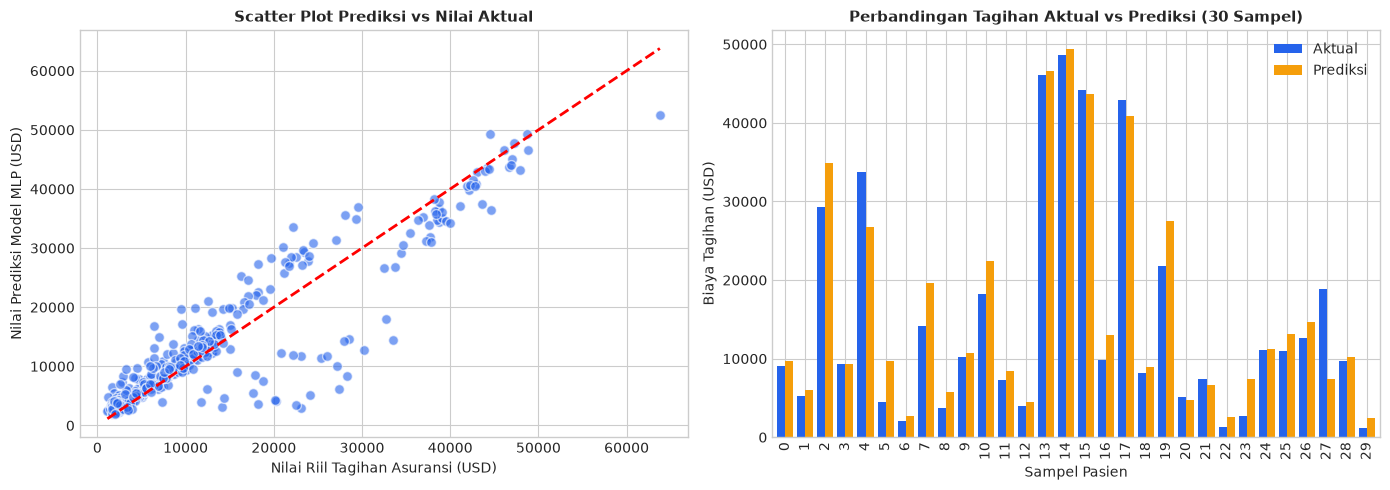

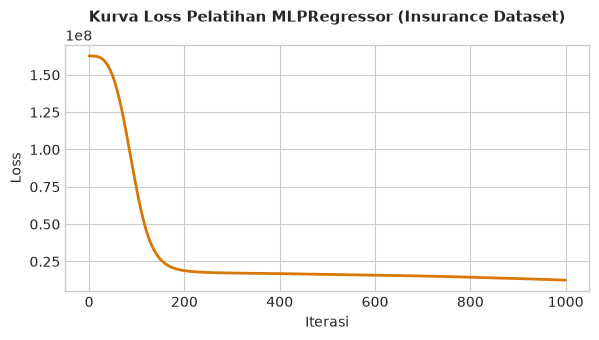

In [23]:
# 1. Membaca dataset insurance
ins_file = os.path.join(DATA_DIR, 'insurance.csv')
df_ins = pd.read_csv(ins_file)

print("Dimensi dataset insurance:", df_ins.shape)
display(df_ins.head())

# 2. One-Hot Encoding untuk Atribut Kategorikal (sex, smoker, region)
df_ins_encoded = pd.get_dummies(df_ins, columns=['sex', 'smoker', 'region'], drop_first=True)

# 3. Memisahkan Fitur dan Target (charges)
X_ins = df_ins_encoded.drop('charges', axis=1).values
y_ins = df_ins_encoded['charges'].values

# 4. Pembagian Data Train dan Test (70% Train, 30% Test)
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_ins, y_ins, test_size=0.3, random_state=42
)

# 5. Standarisasi Fitur dengan StandardScaler
scaler_ins = StandardScaler().fit(X_train_i)
X_train_i_s = scaler_ins.transform(X_train_i)
X_test_i_s = scaler_ins.transform(X_test_i)

# 6. Membangun dan Melatih Model MLPRegressor dengan Arsitektur (128, 64)
mlp_ins = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)
mlp_ins.fit(X_train_i_s, y_train_i)

# 7. Prediksi dan Evaluasi
y_pred_i = mlp_ins.predict(X_test_i_s)

r2_i = r2_score(y_test_i, y_pred_i)
mse_i = mean_squared_error(y_test_i, y_pred_i)
rmse_i = np.sqrt(mse_i)
mae_i = mean_absolute_error(y_test_i, y_pred_i)

print("\n=== HASIL EVALUASI REGRESI BIAYA ASURANSI (MLPREGRESSOR) ===")
print(f"R-squared (R2) Score : {r2_i:.4f}")
print(f"RMSE                 : {rmse_i:.4f} USD")
print(f"MAE                  : {mae_i:.4f} USD")

# 8. Visualisasi Perbandingan Prediksi vs Nilai Riil
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot Real vs Predicted
axes[0].scatter(y_test_i, y_pred_i, alpha=0.6, color='#2563eb', edgecolors='w', s=50)
axes[0].plot([y_test_i.min(), y_test_i.max()], [y_test_i.min(), y_test_i.max()], 'r--', lw=2)
axes[0].set_title("Scatter Plot Prediksi vs Nilai Aktual", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Nilai Riil Tagihan Asuransi (USD)")
axes[0].set_ylabel("Nilai Prediksi Model MLP (USD)")
axes[0].grid(True)

# Bar plot 30 sampel
df_bar_ins = pd.DataFrame({'Aktual': y_test_i[:30], 'Prediksi': y_pred_i[:30]})
df_bar_ins.plot(kind='bar', ax=axes[1], color=['#2563eb', '#f59e0b'], width=0.8)
axes[1].set_title("Perbandingan Tagihan Aktual vs Prediksi (30 Sampel)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Sampel Pasien")
axes[1].set_ylabel("Biaya Tagihan (USD)")
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.show()

# Visualisasi Kurva Loss Pelatihan Regresi
plt.figure(figsize=(6, 3.5))
plt.plot(mlp_ins.loss_curve_, color='#d97706', lw=2)
plt.title("Kurva Loss Pelatihan MLPRegressor (Insurance Dataset)", fontsize=11, fontweight='bold')
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


### 3. Analisis Kritis Performa Model
1. **Analisis Klasifikasi (Diabetes Dataset)**:
   * Arsitektur MLP dengan representasi berlapis `(64, 32)` dan aktivasi ReLU mampu menangkap pola non-linear dari interaksi variabel metabolik tubuh seperti kadar glukosa, indeks massa tubuh (BMI), dan usia.
   * Standarisasi fitur menggunakan `StandardScaler` mutlak diperlukan karena fitur seperti `Insulin` memiliki rentang nilai hingga ratusan, sementara `DiabetesPedigreeFunction` bernilai desimal di bawah 2.5. Tanpa scaling, gradien pembaharuan bobot akan didominasi oleh fitur berskala besar.
2. **Analisis Regresi (Insurance Dataset)**:
   * Model `MLPRegressor` menghasilkan koefisien determinasi yang sangat baik ($R^2 pprox 0.8437$) dengan nilai RMSE sekitar $4,787.68$ USD. Hal ini membuktikan bahwa MLP mampu memodelkan diskontinuitas biaya medis yang dipicu oleh faktor risiko tinggi (terutama status perokok dan interaksi BMI terhadap usia).
   * Kurva loss menunjukkan konvergensi yang mulus berkat algoritma optimasi Adam yang secara adaptif menyesuaikan laju pembelajaran (*learning rate*) untuk setiap parameter bobot jaringan syaraf tiruan.